# Lesson 21 - The ship types we left out, and PANN embeddings

Since lesson 13 six of the dataset's twelve classes were left out:

| Left out | Ships | Clips |
|---|---|---|
| sailing | 212 | 3,601 |
| other (the dataset's own class) | 169 | 3,601 |
| passenger ship | 110 | 3,600 |
| rescue | 23 | 3,600 |
| dredger | 6 | 3,601 |
| pilot vessel | 2 | 3,601 |

A real system will hear these too. Three experiments:

- **A. An "other" class:** all left-out types as one more class.
- **B. "Unknown":** train on our five classes only and answer "unknown" when the model is not sure. The threshold
  is set on the validation clips so that 95 % of known clips are still answered; the left-out ships (never in
  training) show how many unknown ships it catches.
- **C. PANN embeddings:** CNN14 (Kong et al., 2020), pretrained on AudioSet (about 2 million YouTube clips, 527
  sound types such as "ship", "boat", "engine"). Each clip becomes 2,048 numbers, reduced to 256 by PCA (fitted on
  training + validation clips). Alone, and next to our 144 engineered features.

The six known classes keep the folds of lessons 13-20; the left-out ships get their own five folds by ship. Every
merged class gets the same total weight (lesson 20).

```
python src/panns_features.py   # one pass over the audio: PANN embeddings + engineered features (10 min, GPU)
python src/open_set.py         # experiments A, B, C -> runs/open_set/ (30 min, CPU)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import open_set as O

s = json.loads((O.OUT_DIR / "results.json").read_text())
res = pd.DataFrame(s["results"])
pd.set_option("display.width", 160)


def fmt(g, col):
    return (100 * g[col].mean()).round(1).astype(str) + " ± " + (100 * g[col].std()).round(1).astype(str)

## A. An "other" class

In [2]:
a = res[res.experiment == "A"]
g = a.groupby("grouping")
print(pd.DataFrame({"per clip": fmt(g, "balanced_accuracy"), "per ship": fmt(g, "per_ship_balanced_accuracy")}))
rec = pd.DataFrame(list(a.per_class_recall)).assign(grouping=a.grouping.values)
print("\nrecall per class, per clip (%):")
print((100 * rec.groupby("grouping").mean()).round(1).to_string())

                     per clip    per ship
grouping                                 
4 classes + other  69.6 ± 0.9  77.6 ± 1.4
5 classes + other  61.9 ± 0.6  70.7 ± 2.8

recall per class, per clip (%):
                   background  cargo + tanker  fishing  pleasurecraft   tug  other  fishing + tug
grouping                                                                                         
4 classes + other        84.5            94.7      NaN           59.9   NaN   41.4           67.4
5 classes + other        83.9            94.5     39.4           60.2  58.5   35.0            NaN


- **"Other" is recognised only 35-41 % of the time.** It mixes very different boats (sailing yachts, passenger
  ferries, rescue boats, dredgers), so it has no sound of its own.
- **Adding it costs about 8-10 points overall:** five classes + other 61.9 % per clip (70.7 % per ship) against
  70.0 % without; four classes + other 69.6 % (77.6 %) against 80.2 %. The other classes lose a little too (pleasure
  craft 64 → 60 %), because "other" takes some of their clips.

## B. "Unknown" from low confidence

In [3]:
b = res[res.experiment == "B"]
print((100 * b[["known_accepted", "unknown_rejected", "auroc_clip", "auroc_ship"]].mean()).round(1).to_frame("mean (%)"))
print("\nunknown clips rejected, by type (%):")
print((100 * pd.DataFrame(list(b.rejected_by_type)).mean()).round(1).to_frame().T.to_string(index=False))
print("\nwhat the unknown clips were called (%):")
print((100 * pd.DataFrame(list(b.unknown_called_as)).mean()).round(1).to_frame().T.to_string(index=False))

                  mean (%)
known_accepted        95.2
unknown_rejected       9.5
auroc_clip            67.0
auroc_ship            83.1

unknown clips rejected, by type (%):
 dredger  other  passengership  pilotvessel  rescue  sailing
    12.0    8.3            7.2          8.3    13.1      9.1

what the unknown clips were called (%):
 background  cargo + tanker  fishing  pleasurecraft  tug
       14.1            11.9     17.7           26.6 29.7


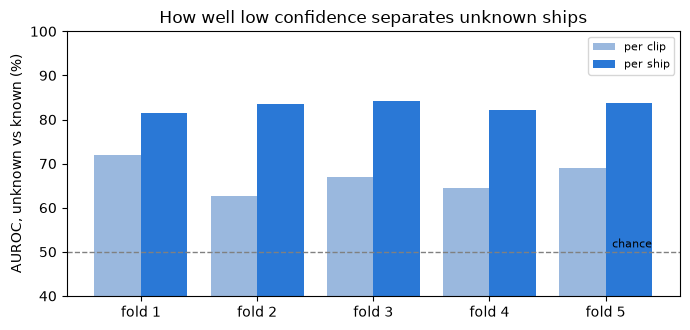

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(b))
ax.bar(x - 0.2, 100 * b.auroc_clip, 0.4, color="#9ab8de", label="per clip")
ax.bar(x + 0.2, 100 * b.auroc_ship, 0.4, color="#2a78d6", label="per ship")
ax.axhline(50, color="grey", ls="--", lw=1); ax.text(4.4, 51, "chance", ha="right", fontsize=8)
ax.set_xticks(x, [f"fold {k}" for k in b.fold]); ax.set_ylim(40, 100); ax.set_ylabel("AUROC, unknown vs known (%)")
ax.legend(fontsize=8); ax.set_title("How well low confidence separates unknown ships"); plt.tight_layout(); plt.show()

- **Per clip, "unknown" hardly works:** with 95 % of known clips answered, only 9.5 % of unknown clips are
  rejected (AUROC 67 %). The model is as confident about a sailing boat as about a tug; unknown clips are mostly
  called tug (30 %) or pleasure craft (27 %).
- **Per ship it is much better:** AUROC 83 %, every fold 81-84 %. Averaged over a passage, an unknown ship's
  answers disagree more, and the confidence drops.
- So "unknown" should be decided per ship, with a threshold chosen for the use (how many known ships may be
  rejected), not per clip.

## C. PANN embeddings (five classes)

In [5]:
c = res[res.experiment == "C"]
g = c.groupby(["features", "model"], sort=False)
print(pd.DataFrame({"per clip": fmt(g, "balanced_accuracy"), "per ship": fmt(g, "per_ship_balanced_accuracy")}))
print(f"\nvariance kept by 256 PCA components: {c.pca_variance.mean():.1%}")
for m in ("gradient boosting", "logistic regression"):
    x = c[c.model == m].pivot(index="fold", columns="features", values="per_ship_balanced_accuracy")
    d = 100 * (x["PANN (256) + engineered (144)"] - x["engineered (144)"])
    print(f"{m}: PANN + engineered minus engineered, per ship, by fold: {d.round(1).tolist()}")

                                                     per clip    per ship
features                      model                                      
PANN (256)                    logistic regression  62.0 ± 0.8  71.6 ± 1.5
                              gradient boosting    61.4 ± 0.6  71.8 ± 0.5
PANN (256) + engineered (144) logistic regression  69.2 ± 0.8  77.8 ± 1.3
                              gradient boosting    70.4 ± 1.1  79.4 ± 1.6
engineered (144)              logistic regression  68.6 ± 1.7  75.6 ± 2.0
                              gradient boosting    70.0 ± 1.2  78.7 ± 2.9

variance kept by 256 PCA components: 98.9%
gradient boosting: PANN + engineered minus engineered, per ship, by fold: [1.6, 2.2, 2.2, -1.8, -0.9]
logistic regression: PANN + engineered minus engineered, per ship, by fold: [2.0, 3.3, 2.7, 0.1, 3.0]


- **PANN alone is clearly worse than our features:** 61.4 % per clip and 71.8 % per ship (gradient boosting),
  against 70.0 % and 78.7 % with the 144 engineered numbers. It was trained on sound in air.
- **Added to our features it helps a little:** gradient boosting 70.4 % / 79.4 % (+0.4 / +0.7, within the fold
  spread, and worse on 2 of 5 folds per ship); logistic regression 69.2 % / 77.8 % (+0.6 / +2.2, better on every
  fold per ship).
- Cost: one 10-minute pass on the GPU, and 256 more numbers per clip.

## What it means

| Test, 5 folds | Per clip | Per ship |
|---|---|---|
| 5 classes, engineered, gradient boosting (lesson 20) | 70.0 % | 78.7 % |
| 5 classes + other | 61.9 % | 70.7 % |
| 4 classes + other | 69.6 % | 77.6 % |
| 5 classes, PANN + engineered, gradient boosting | 70.4 % | 79.4 % |
| Unknown ships: AUROC (low confidence = unknown) | 67 % | 83 % |

- **The left-out types are the honest limit:** as an "other" class they are hard to recognise, and as unknowns
  they are only caught per ship. A system for real traffic should decide per ship and flag low-confidence ships.
- **PANNs is not worth its cost here:** alone it is 9 points worse than our features; together, at most a point or
  two, not on every fold.